# Unemployment Analysis in India (with COVID-19 Impact)
**Objective:** Analyse regional and temporal unemployment trends in India and measure the impact of the COVID-19 lockdown.

**Dataset:** *Unemployment in India* (Kaggle). Place `Unemployment in India.csv` in the same folder as this notebook.

In [1]:
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14

## 1. Load the Data

In [2]:
files = glob.glob("*nemployment*.csv")
assert files, "Place the Kaggle 'Unemployment in India.csv' file next to this notebook."
df = pd.read_csv(files[0])
print("Loaded:", files[0])
df.head()

Loaded: Unemployment in India.csv


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 2. Inspect Shape, Types and Missing Values

In [3]:
print("Shape:", df.shape)
print()
df.info()

Shape: (768, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [4]:
print("Null values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Null values per column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Duplicate rows: 27


## 3. Cleaning and Type Conversion
Column names and text values carry stray whitespace in this dataset, and `Date` is stored as text (day-first).

In [5]:
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation",
    "Region.1": "Zone",
})

df = df.dropna(how="all").drop_duplicates().reset_index(drop=True)

for col in ["Region", "Frequency", "Zone"]:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

df["Date"] = pd.to_datetime(df["Date"].astype(str).str.strip(), dayfirst=True)
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")
df["Year"] = df["Date"].dt.year

for col in ["Unemployment_Rate", "Employed", "Labour_Participation"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Nulls after cleaning:\n", df.isnull().sum())
print("\nDate range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Regions:", df["Region"].nunique())
df.dtypes

Nulls after cleaning:
 Region                  0
Date                    0
Frequency               0
Unemployment_Rate       0
Employed                0
Labour_Participation    0
Area                    0
Month                   0
Month_Name              0
Year                    0
dtype: int64

Date range: 2019-05-31 to 2020-06-30
Regions: 28


Region                          object
Date                    datetime64[ns]
Frequency                       object
Unemployment_Rate              float64
Employed                       float64
Labour_Participation           float64
Area                            object
Month                            int32
Month_Name                      object
Year                             int32
dtype: object

## 4. Descriptive Statistics

In [6]:
df[["Unemployment_Rate", "Employed", "Labour_Participation"]].describe().round(2)

,Unemployment_Rate,Employed,Labour_Participation
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


## 5. Region-wise Average Unemployment Rate
Average of the monthly estimates for each state across the whole period.

In [7]:
region_avg = (df.groupby("Region")["Unemployment_Rate"].mean()
                .sort_values(ascending=False).round(2))
region_avg.to_frame("Avg Unemployment Rate (%)")

,Avg Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


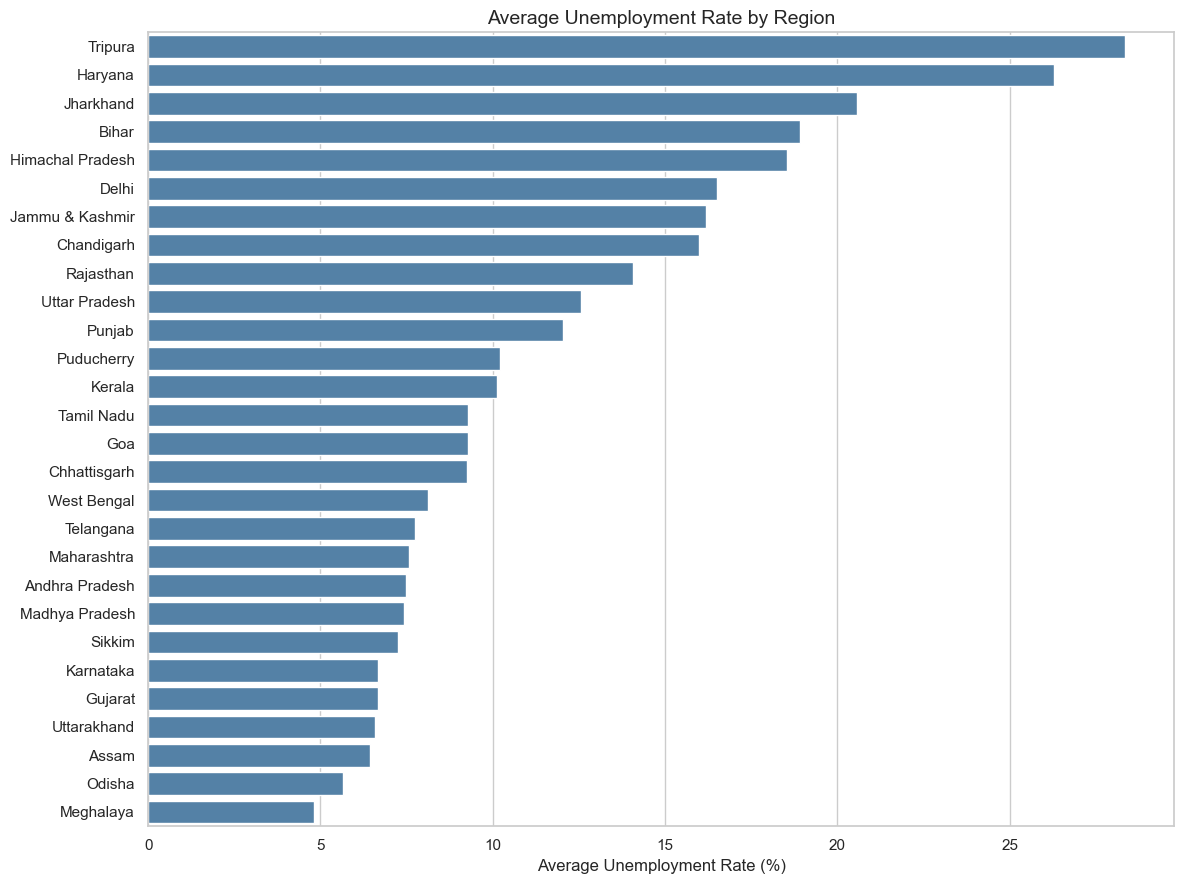

Highest: Tripura (28.35%)
Lowest : Meghalaya (4.8%)


In [8]:
plt.figure(figsize=(12, 9))
sns.barplot(x=region_avg.values, y=region_avg.index, color="steelblue")
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(f"Highest: {region_avg.index[0]} ({region_avg.iloc[0]}%)")
print(f"Lowest : {region_avg.index[-1]} ({region_avg.iloc[-1]}%)")

## 6. Top 10 States with the Highest Average Unemployment Rate

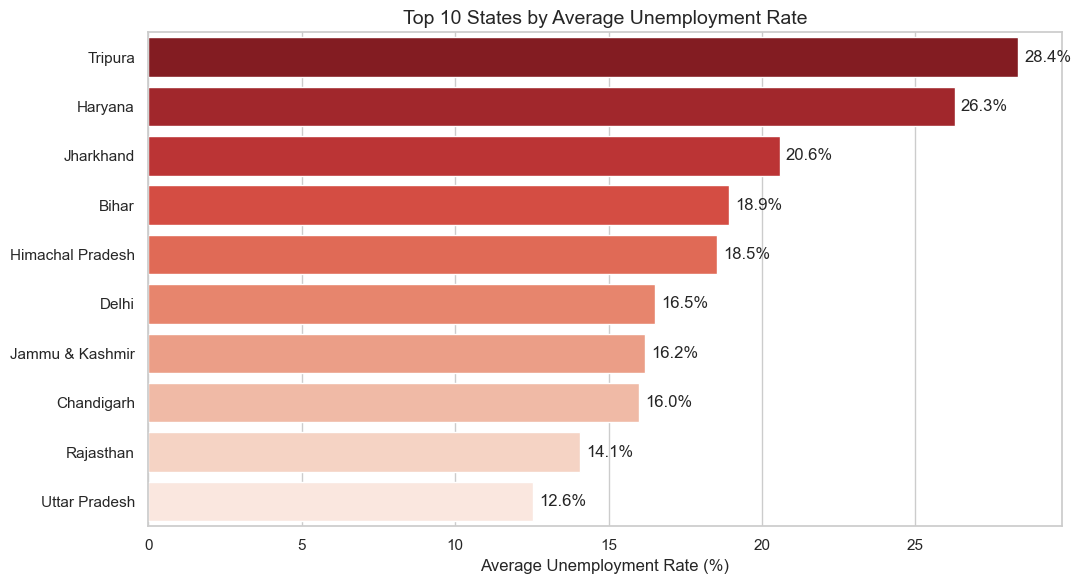

Top 3: Tripura (28.35%), Haryana (26.28%), Jharkhand (20.58%)


In [9]:
top10 = region_avg.head(10)

plt.figure(figsize=(11, 6))
ax = sns.barplot(x=top10.values, y=top10.index, palette="Reds_r")
for i, v in enumerate(top10.values):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center")
plt.title("Top 10 States by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Top 3:", ", ".join(f"{r} ({v}%)" for r, v in top10.head(3).items()))

## 7. Month-wise Trend (All-India Average)

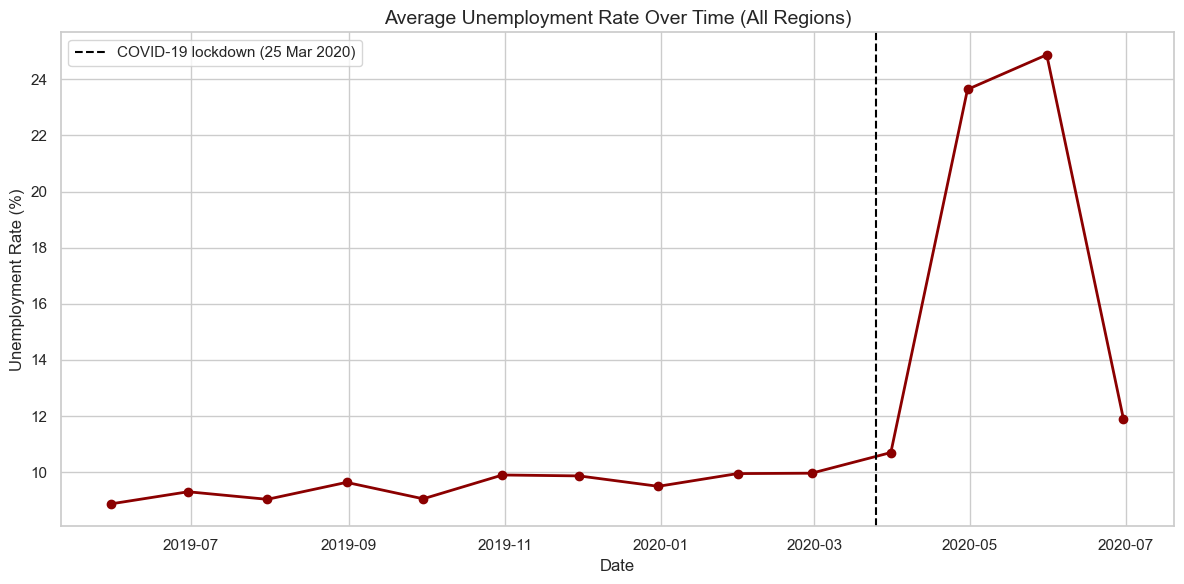

Peak month: May 2020 at 24.88%
Lowest month: May 2019 at 8.87%


In [10]:
monthly = df.groupby("Date")["Unemployment_Rate"].mean()

plt.figure(figsize=(12, 6))
plt.plot(monthly.index, monthly.values, marker="o", linewidth=2, color="darkred")
plt.axvline(pd.Timestamp("2020-03-25"), color="black", linestyle="--", label="COVID-19 lockdown (25 Mar 2020)")
plt.title("Average Unemployment Rate Over Time (All Regions)")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

peak = monthly.idxmax()
print(f"Peak month: {peak.strftime('%B %Y')} at {monthly.max():.2f}%")
print(f"Lowest month: {monthly.idxmin().strftime('%B %Y')} at {monthly.min():.2f}%")

## 8. Time Series for Major States

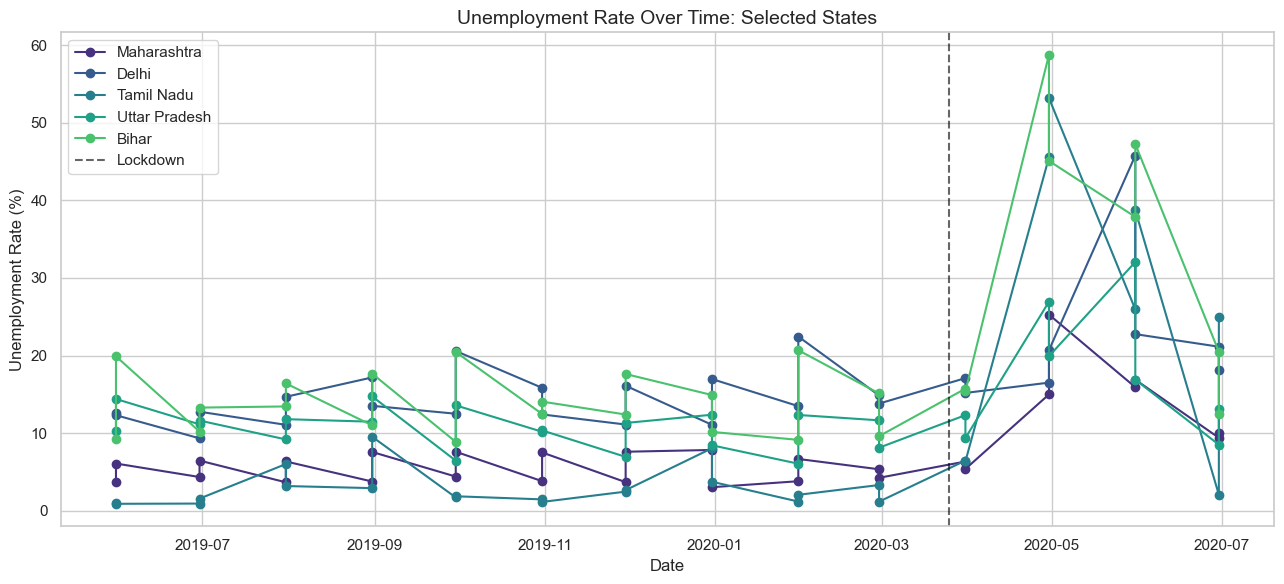

Maharashtra: peak 25.3% in Apr 2020
Delhi: peak 45.8% in May 2020
Tamil Nadu: peak 53.2% in Apr 2020
Uttar Pradesh: peak 32.1% in May 2020
Bihar: peak 58.8% in Apr 2020


In [11]:
wanted = ["Maharashtra", "Delhi", "Tamil Nadu", "Uttar Pradesh", "Bihar"]
states = [s for s in wanted if s in df["Region"].unique()]
if len(states) < 3:
    states = df["Region"].value_counts().head(5).index.tolist()

plt.figure(figsize=(13, 6))
for s in states:
    sub = df[df["Region"] == s].sort_values("Date")
    plt.plot(sub["Date"], sub["Unemployment_Rate"], marker="o", label=s)
plt.axvline(pd.Timestamp("2020-03-25"), color="black", linestyle="--", alpha=0.6, label="Lockdown")
plt.title("Unemployment Rate Over Time: Selected States")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

for s in states:
    sub = df[df["Region"] == s]
    row = sub.loc[sub["Unemployment_Rate"].idxmax()]
    print(f"{s}: peak {row['Unemployment_Rate']:.1f}% in {row['Date'].strftime('%b %Y')}")

## 9. Rural vs Urban Unemployment

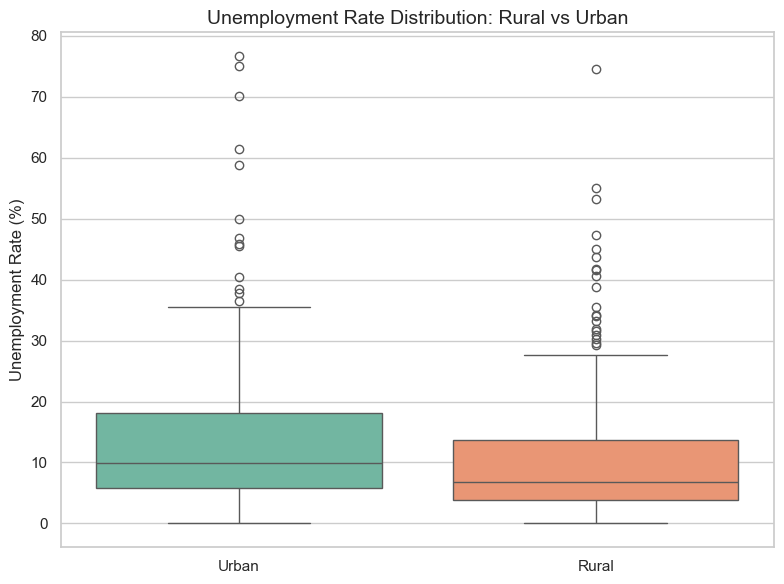

Area
Rural    10.32
Urban    13.17
Name: Unemployment_Rate, dtype: float64


In [17]:
area = df["Area"].str.strip()
order = df.groupby(area)["Unemployment_Rate"].median().sort_values(ascending=False).index

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x=area, y="Unemployment_Rate", order=order, palette="Set2")
plt.title("Unemployment Rate Distribution: Rural vs Urban")
plt.xlabel("")
plt.ylabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

print(df.groupby(area)["Unemployment_Rate"].mean().round(2))

## 10. Correlation Heatmap
Relationship between unemployment rate, employment (number employed) and labour participation rate.

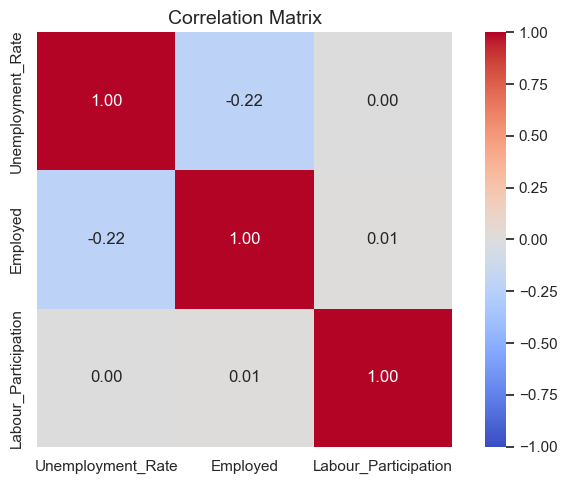

Unemployment vs Labour Participation: 0.00
Unemployment vs Employed            : -0.22


In [13]:
corr = df[["Unemployment_Rate", "Employed", "Labour_Participation"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

print(f"Unemployment vs Labour Participation: {corr.loc['Unemployment_Rate', 'Labour_Participation']:.2f}")
print(f"Unemployment vs Employed            : {corr.loc['Unemployment_Rate', 'Employed']:.2f}")

## 11. Pre-COVID vs Post-COVID Comparison
The data is split at the national lockdown start date, **25 March 2020**.

In [14]:
cutoff = pd.Timestamp("2020-03-25")
df["Period"] = np.where(df["Date"] < cutoff, "Pre-COVID", "Post-COVID")

summary = (df.groupby("Period")[["Unemployment_Rate", "Employed", "Labour_Participation"]]
             .mean().round(2).loc[["Pre-COVID", "Post-COVID"]])
summary

,Unemployment_Rate,Employed,Labour_Participation
Period,,,
Pre-COVID,9.51,7466027.87,43.89
Post-COVID,17.77,6517203.34,39.33


Mean unemployment rate  Pre-COVID : 9.51%
Mean unemployment rate  Post-COVID: 17.77%
Change: +8.26 percentage points (+86.9%)


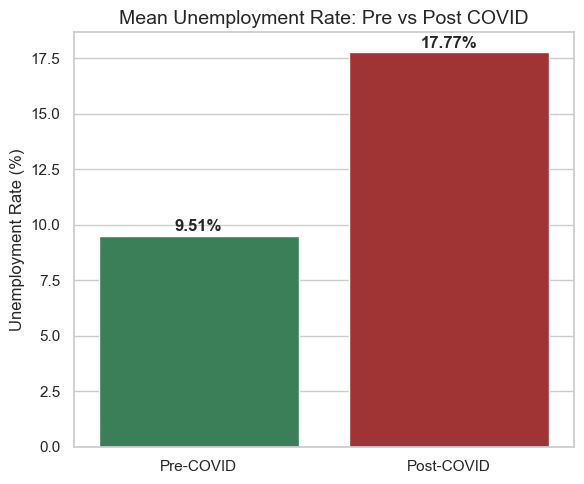

In [15]:
pre = summary.loc["Pre-COVID", "Unemployment_Rate"]
post = summary.loc["Post-COVID", "Unemployment_Rate"]
print(f"Mean unemployment rate  Pre-COVID : {pre:.2f}%")
print(f"Mean unemployment rate  Post-COVID: {post:.2f}%")
print(f"Change: {post - pre:+.2f} percentage points ({(post - pre) / pre * 100:+.1f}%)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=summary.index, y=summary["Unemployment_Rate"], palette=["seagreen", "firebrick"], ax=ax)
for i, v in enumerate(summary["Unemployment_Rate"]):
    ax.text(i, v + 0.2, f"{v:.2f}%", ha="center", fontweight="bold")
ax.set_title("Mean Unemployment Rate: Pre vs Post COVID")
ax.set_xlabel("")
ax.set_ylabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

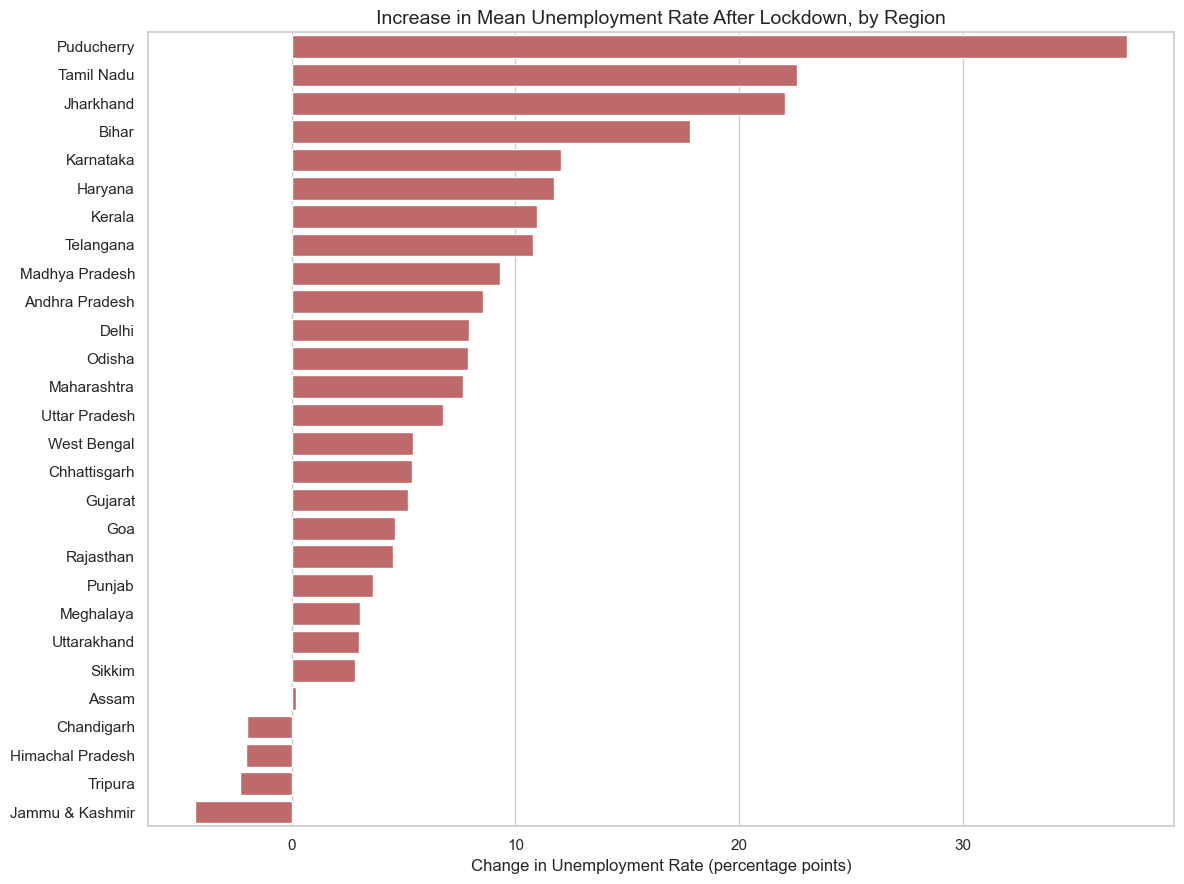

Most affected: Puducherry (+37.4), Tamil Nadu (+22.6), Jharkhand (+22.1)


Period,Post-COVID,Pre-COVID,Change
Region,,,
Puducherry,38.96,1.59,37.36
Tamil Nadu,25.40,2.84,22.57
Jharkhand,36.35,14.28,22.07
Bihar,31.63,13.83,17.80
Karnataka,15.28,3.23,12.05
Haryana,34.65,22.94,11.72
Kerala,17.95,6.99,10.96
Telangana,15.44,4.66,10.79
Madhya Pradesh,14.07,4.74,9.33


In [16]:
by_region = (df.pivot_table(index="Region", columns="Period", values="Unemployment_Rate", aggfunc="mean")
               .dropna())
by_region["Change"] = by_region["Post-COVID"] - by_region["Pre-COVID"]
by_region = by_region.sort_values("Change", ascending=False).round(2)

plt.figure(figsize=(12, 9))
sns.barplot(x=by_region["Change"], y=by_region.index, color="indianred")
plt.title("Increase in Mean Unemployment Rate After Lockdown, by Region")
plt.xlabel("Change in Unemployment Rate (percentage points)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Most affected:", ", ".join(f"{r} ({v:+.1f})" for r, v in by_region["Change"].head(3).items()))
by_region

## 12. Conclusion

The data shows a clear break at the national lockdown. The average unemployment rate across states rose from 9.51% before 25 March 2020 to 17.77% afterwards (+8.26 percentage points), peaking at 24.88% in May 2020.

**Key findings**
- **Regional gaps are wide.** Tripura (28.35%), Haryana (26.28%) and Jharkhand (20.58%) recorded the highest average rates over the period, against 4.80% in Meghalaya, the lowest.
- **The lockdown shock was uneven.** Puducherry (+37.4 pp), Tamil Nadu (+22.6 pp) and Jharkhand (+22.1 pp) saw the largest increases in average unemployment.
- **Linear relationships are weak.** Unemployment shows no correlation with labour participation (0.00) and a weak negative correlation with the estimated number employed (-0.22).
- **Jharkhand stands out.** It combines a high pre-existing rate with one of the largest post-lockdown increases, making it a clear priority for targeted employment support.

**Limitations**
- National figures are unweighted averages of state rates, so they differ from a true labour-force-weighted national rate.
- The dataset runs from May 2019 to June 2020, so the post-lockdown period covers only three months, against eleven months before it.